# Student Performance EDA — Who Needs Learner Support?
**Prepared for the County Director of Education · 1,200 students · 6 counties**

## Summary for the Director
- **Study time is the strongest lever:** study hours correlate r = 0.70 with average score; each extra weekly hour is associated with about **2.1 points** (R² = 0.50).
- **At-risk learners are 99 of 1,200 (8.3%)** and look different from the rest: median 2.1 study hours vs 4.5 overall, attendance 69.0% vs 82.0%.
- **Public-school learners carry the risk:** 10.9% are At Risk vs 1.5% in private schools, and 94 of the 99 At Risk learners are in public schools.
- **County and gender are not good targeting criteria:** county At Risk shares range only 6.4%–9.2% and gender averages differ by 0.2 points.
- **Recommendation:** target by behaviour and school type, not geography (details in Task 9).

## Task 1 · Structure and data quality

In [1]:
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
pd.options.display.float_format = "{:,.2f}".format
df = pd.read_csv("student_performance.csv")
print("shape:", df.shape); print(df.dtypes); df.head()

shape: (1200, 9)
student_id           int64
county                 str
school_type            str
gender                 str
attendance_rate    float64
study_hours        float64
math               float64
english            float64
science            float64
dtype: object


,student_id,county,school_type,gender,attendance_rate,study_hours,math,english,science
0,1,Turkana,Private,M,0.77,6.50,81.00,71.00,73.00
1,2,Nyeri,Private,M,0.97,8.50,100.00,86.00,90.00
2,3,Nyeri,Private,F,0.98,8.00,82.00,89.00,90.00
3,4,Turkana,Public,M,0.93,6.00,83.00,91.00,72.00
4,5,Kisumu,Private,F,0.67,6.10,76.00,69.00,62.00


In [2]:
checks = pd.Series({
    "missing values": int(df.isna().sum().sum()),
    "duplicate rows": int(df.duplicated().sum()),
    "duplicate student_id": int(df.student_id.duplicated().sum()),
    "attendance_rate outside 0-1": int((~df.attendance_rate.between(0,1)).sum()),
    "study_hours <= 0": int((df.study_hours<=0).sum()),
    "scores outside 0-100": int((~df[["math","english","science"]].stack().between(0,100)).sum()),
    "unexpected category labels": int((~df.gender.isin(["F","M"])).sum() + (~df.school_type.isin(["Public","Private"])).sum())})
print(checks.to_string())
print("\nscores equal to 100:", (df[["math","english","science"]]==100).sum().to_dict())

missing values                 0
duplicate rows                 0
duplicate student_id           0
attendance_rate outside 0-1    0
study_hours <= 0               0
scores outside 0-100           0
unexpected category labels     0

scores equal to 100: {'math': 11, 'english': 21, 'science': 16}


**Grain:** one row per student (`student_id` is unique), one observation each — a single snapshot with no dates.
**Variables:** `student_id` (integer identifier); `county`, `school_type`, `gender` (categorical); `attendance_rate` (continuous, share 0–1) and `study_hours` (continuous, hours); `math`, `english`, `science` (integer scores 0–100).
**Data quality:** all checks above return 0 — no missing values, duplicates, out-of-range values or inconsistent labels. One thing to know, not an error: scores are capped at 100 (11 maths, 21 English and 16 science scores sit exactly at the cap), which slightly compresses the top of the range.

## Task 2 · Univariate analysis

In [3]:
num = ["attendance_rate","study_hours","math","english","science"]
u = df[num].agg(["count","mean","median","std","min","max","skew"]).T
u["IQR"] = df[num].quantile(.75) - df[num].quantile(.25)
display(u)
for c in ["county","school_type","gender"]:
    t = df[c].value_counts().to_frame("count"); t["share_%"] = (t["count"]/len(df)*100).round(1); display(t)
q1, q3 = df.study_hours.quantile([.25,.75]); fence = q3 + 1.5*(q3-q1)
out = df[df.study_hours > fence]
print(f"study_hours IQR fence = {fence:.1f}; outliers = {len(out)}; max = {df.study_hours.max()}")

,count,mean,median,std,min,max,skew,IQR
attendance_rate,"1,200.00",0.80,0.82,0.12,0.33,1.00,-0.86,0.17
study_hours,"1,200.00",5.08,4.50,3.03,0.20,23.30,1.17,3.80
math,"1,200.00",71.89,72.00,10.86,37.00,100.00,0.10,14.00
english,"1,200.00",74.52,74.00,10.49,47.00,100.00,0.16,14.00
science,"1,200.00",69.61,69.00,12.02,35.00,100.00,0.11,17.00


,count,share_%
county,,
Mombasa,212,17.70
Kisumu,208,17.30
Nyeri,203,16.90
Nakuru,202,16.80
Turkana,191,15.90
Nairobi,184,15.30


,count,share_%
school_type,,
Public,866,72.20
Private,334,27.80


,count,share_%
gender,,
F,612,51.00
M,588,49.00


study_hours IQR fence = 12.4; outliers = 29; max = 23.3


**Numerical variables.** Attendance is high and **left-skewed** (mean 0.80, median 0.82, skew -0.86): most students attend over 70% of days, with a tail of low attenders. Study hours are **right-skewed** (mean 5.1, median 4.5, skew 1.17, SD 3.0). The three subjects are roughly symmetric; English is highest (mean 74.5), maths 71.9 and science lowest (69.6) with the widest spread (SD 12.0).
**Categorical variables.** Counties are close to evenly sized (184–212 students each); 72.2% of students are in public schools; gender is balanced (51.0% female).
**Outliers in `study_hours`.** By the IQR rule (fence 12.4 h), **29 students (2.4%)** are outliers, the highest at 23.3 h. They form the natural long tail of a right-skewed variable rather than obvious errors, so I **keep them** but check the effect on any regression (see Task 7).

## Task 3 · `average_score` and `performance_band`

In [4]:
df["average_score"] = df[["math","english","science"]].mean(axis=1)
df["performance_band"] = pd.cut(df.average_score, bins=[-np.inf, 60, 75, np.inf],
                                labels=["At Risk","Meeting","Exceeding"], right=False)
t = df.performance_band.value_counts().to_frame("students"); t["share_%"] = (t.students/len(df)*100).round(1); display(t)
df[["student_id","math","english","science","average_score","performance_band"]].head()

,students,share_%
performance_band,,
Meeting,672,56.00
Exceeding,429,35.80
At Risk,99,8.20


,student_id,math,english,science,average_score,performance_band
0,1,81.00,71.00,73.00,75.00,Exceeding
1,2,100.00,86.00,90.00,92.00,Exceeding
2,3,82.00,89.00,90.00,87.00,Exceeding
3,4,83.00,91.00,72.00,82.00,Exceeding
4,5,76.00,69.00,62.00,69.00,Meeting


`average_score` is the mean of the three subjects. `pd.cut` with `right=False` gives At Risk **< 60**, Meeting **60 to < 75**, Exceeding **≥ 75**. Result: **99 At Risk (8.3%)**, 672 Meeting (56.0%), 429 Exceeding (35.8%).

## Task 4 · Bivariate: correlations

In [5]:
cols = ["attendance_rate","study_hours","math","english","science","average_score"]
corr = df[cols].corr().round(2); display(corr)
corr["average_score"].drop("average_score").sort_values(ascending=False)

,attendance_rate,study_hours,math,english,science,average_score
attendance_rate,1.00,-0.03,0.30,0.33,0.26,0.36
study_hours,-0.03,1.00,0.56,0.62,0.55,0.70
math,0.30,0.56,1.00,0.56,0.46,0.81
english,0.33,0.62,0.56,1.00,0.50,0.83
science,0.26,0.55,0.46,0.50,1.00,0.82
average_score,0.36,0.70,0.81,0.83,0.82,1.00


english           0.83
science           0.82
math              0.81
study_hours       0.70
attendance_rate   0.36
Name: average_score, dtype: float64

The three subject scores correlate very strongly with `average_score` (r = 0.83, 0.82, 0.81), but that is by construction — the average is built from them. Among the *explanatory* variables the strongest relationships are:
1. **Study hours (r = 0.70):** a strong positive link — more study time goes with higher scores, and it is the single most important factor in this data.
2. **Attendance rate (r = 0.36):** a moderate positive link — students who attend more score higher.
3. **Subject cross-correlations (0.56, 0.50, 0.46):** learners who do well in one subject tend to do well in all, so the programme need not be subject-specific.

Study hours and attendance are almost uncorrelated with each other (r = -0.03), so they act as separate, additive drivers. Correlation is not causation: these are associations in observational data.

## Task 5 · Average scores by gender, school type and county

In [6]:
for g in ["gender","school_type"]:
    display(df.groupby(g).agg(students=("student_id","count"), avg_score=("average_score","mean"),
            at_risk_pct=("performance_band", lambda s:(s=="At Risk").mean()*100)).round(1))
cty = df.groupby("county").agg(students=("student_id","count"), avg_score=("average_score","mean"),
        at_risk=("performance_band", lambda s:(s=="At Risk").sum()),
        at_risk_pct=("performance_band", lambda s:(s=="At Risk").mean()*100)).round(1).sort_values("at_risk_pct", ascending=False)
display(cty)
# is the county spread bigger than chance? chi-square for equal at-risk rates
p = (df.performance_band=="At Risk").mean(); exp = cty.students*p
chi2 = ((cty.at_risk-exp)**2/exp).sum(); print(f"chi-square = {chi2:.2f} (5 df, 5% critical value = 11.07)")

,students,avg_score,at_risk_pct
gender,,,
F,612,72.10,9.30
M,588,71.90,7.10


,students,avg_score,at_risk_pct
school_type,,,
Private,334,76.00,1.50
Public,866,70.50,10.90


,students,avg_score,at_risk,at_risk_pct
county,,,,
Nairobi,184,72.00,17,9.20
Mombasa,212,72.20,19,9.00
Nyeri,203,71.90,18,8.90
Kisumu,208,73.10,17,8.20
Turkana,191,71.00,15,7.90
Nakuru,202,71.80,13,6.40


chi-square = 1.29 (5 df, 5% critical value = 11.07)


**Gender:** negligible difference — female 72.1 vs male 71.9 average points; At Risk shares 9.3% (F) vs 7.1% (M), a 2-point difference on roughly 600 students each that is not conclusive and too small to base targeting on.
**School type:** **private 76.0 vs public 70.5 (5.5-point gap)**, and the At Risk share is 1.5% in private vs 10.9% in public schools.
**County:** average scores range only from 71.0 (Turkana) to 73.1 (Kisumu). **Nairobi has the highest share of At Risk learners (9.2%, 17 of 184)**, followed by Mombasa (9.0%); Nakuru is lowest (6.4%). **But this ranking should not drive budget:** a chi-square test gives 1.29, far below the 11.07 needed for significance, and Nairobi's own 95% margin is about ±4.2 points — so the county differences are consistent with chance.

## Task 6 · Multivariate: does the school-type gap persist?

In [7]:
df["attendance_band"] = pd.cut(df.attendance_rate, [0,.7,.8,.9,1.0], labels=["≤70%","71–80%","81–90%","91–100%"])
df["study_quartile"] = pd.qcut(df.study_hours, 4, labels=["Q1 (lowest)","Q2","Q3","Q4 (highest)"])
pa = df.pivot_table(index="attendance_band", columns="school_type", values="average_score", aggfunc="mean", observed=True)
pa["gap (Private-Public)"] = pa.Private - pa.Public; display(pa.round(1))
ps = df.pivot_table(index="study_quartile", columns="school_type", values="average_score", aggfunc="mean", observed=True)
ps["gap (Private-Public)"] = ps.Private - ps.Public; display(ps.round(1))
display(df.pivot_table(index="study_quartile", columns="school_type", values="student_id", aggfunc="count", observed=True))

school_type,Private,Public,gap (Private-Public)
attendance_band,,,
≤70%,71.50,64.90,6.60
71–80%,75.50,68.80,6.70
81–90%,77.00,72.40,4.60
91–100%,79.40,74.20,5.20


school_type,Private,Public,gap (Private-Public)
study_quartile,,,
Q1 (lowest),69.50,63.80,5.70
Q2,74.90,67.10,7.80
Q3,76.20,71.20,5.00
Q4 (highest),83.60,80.10,3.60


school_type,Private,Public
study_quartile,,
Q1 (lowest),84,227
Q2,86,216
Q3,82,206
Q4 (highest),82,217


**Yes, the gap persists.** Private-school students out-score public-school students in **every** attendance band (gap 4.6 to 6.7 points) and in **every** study-hour quartile (gap 3.6 to 7.8 points). It is therefore not explained by private-school students simply attending more or studying more. The gap is smallest in the top study-hour quartile (3.6 points) — heavy study narrows but does not close it. Each cell has at least 80 students, so the comparisons are reasonably stable.
Risk also climbs steeply as behaviour worsens: At Risk share is **23.9%** among students with ≤70% attendance vs **2.3%** at 91–100%, and **21.2%** in the lowest study-hour quartile vs **0.3%** in the highest.

## Task 7 · Trend: `average_score` vs `study_hours`

In [8]:
slope, intercept = np.polyfit(df.study_hours, df.average_score, 1)
r2 = np.corrcoef(df.study_hours, df.average_score)[0,1]**2
print(f"average_score = {slope:.2f} x study_hours + {intercept:.1f}   (R² = {r2:.2f})")
print("prediction at the maximum study_hours (%.1f h): %.1f" % (df.study_hours.max(), slope*df.study_hours.max()+intercept))

average_score = 2.12 x study_hours + 61.3   (R² = 0.50)
prediction at the maximum study_hours (23.3 h): 110.6


**Trend line:** average_score = 2.12 × study_hours + 61.3, **R² = 0.50**.
**Slope meaning:** each additional hour of weekly study is associated with about **2.1 more points** on the average score.
**Limitation:** R² of 0.50 means about half the variation is unexplained, and a straight line extrapolates impossibly — at the maximum 23.3 hours it predicts 111, above the 100-point cap — so it should not be used to predict individual students or extreme study times.

## Task 8 · Charts (pandas `.plot()`, saved to `figures/`)

In [9]:
import os; os.makedirs("figures", exist_ok=True)
def save(ax, name):
    ax.figure.tight_layout(); ax.figure.savefig(f"figures/{name}.png", dpi=150); plt.close(ax.figure)
ax = df.average_score.plot.hist(bins=25, edgecolor="white", figsize=(7,4), title="Distribution of average score")
ax.axvline(60, color="red", linestyle="--"); ax.set_xlabel("Average score"); save(ax, "01_hist_average_score")
ax = df.study_hours.plot.hist(bins=30, edgecolor="white", figsize=(7,4), title="Weekly study hours (right-skewed)")
ax.set_xlabel("Study hours"); save(ax, "02_hist_study_hours")
ax = (cty.sort_values("at_risk_pct")["at_risk_pct"]).plot.barh(figsize=(7,4), title="Share of At Risk learners by county (%)")
ax.set_xlabel("% At Risk"); save(ax, "03_bar_at_risk_by_county")
ax = df.boxplot(column="average_score", by="school_type", figsize=(6,4)); ax.set_title("Average score by school type"); ax.figure.suptitle("")
ax.set_ylabel("Average score"); save(ax, "04_box_score_by_school_type")
ax = df.groupby("study_quartile", observed=True).average_score.mean().plot.bar(figsize=(7,4), title="Average score by study-hour quartile", rot=0)
ax.set_ylabel("Average score"); save(ax, "05_bar_score_by_study_quartile")
ax = df.plot.scatter("study_hours", "average_score", alpha=.35, figsize=(7,4), title="Study hours vs average score")
xs = np.linspace(df.study_hours.min(), df.study_hours.max(), 50); ax.plot(xs, slope*xs+intercept, color="red"); save(ax, "06_scatter_trend")
sorted(os.listdir("figures"))

['01_hist_average_score.png',
 '02_hist_study_hours.png',
 '03_bar_at_risk_by_county.png',
 '04_box_score_by_school_type.png',
 '05_bar_score_by_study_quartile.png',
 '06_scatter_trend.png']

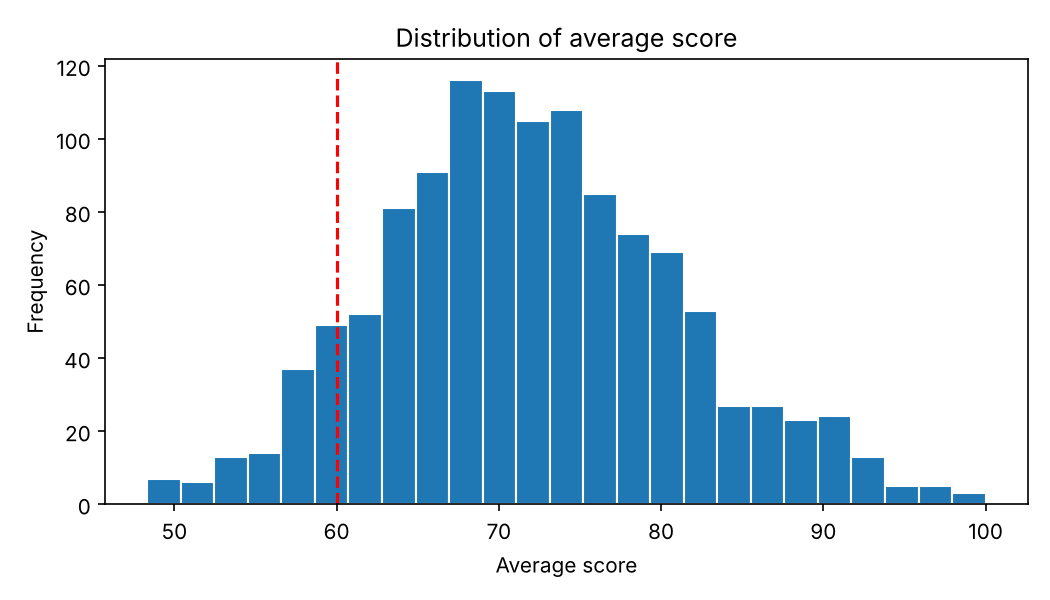

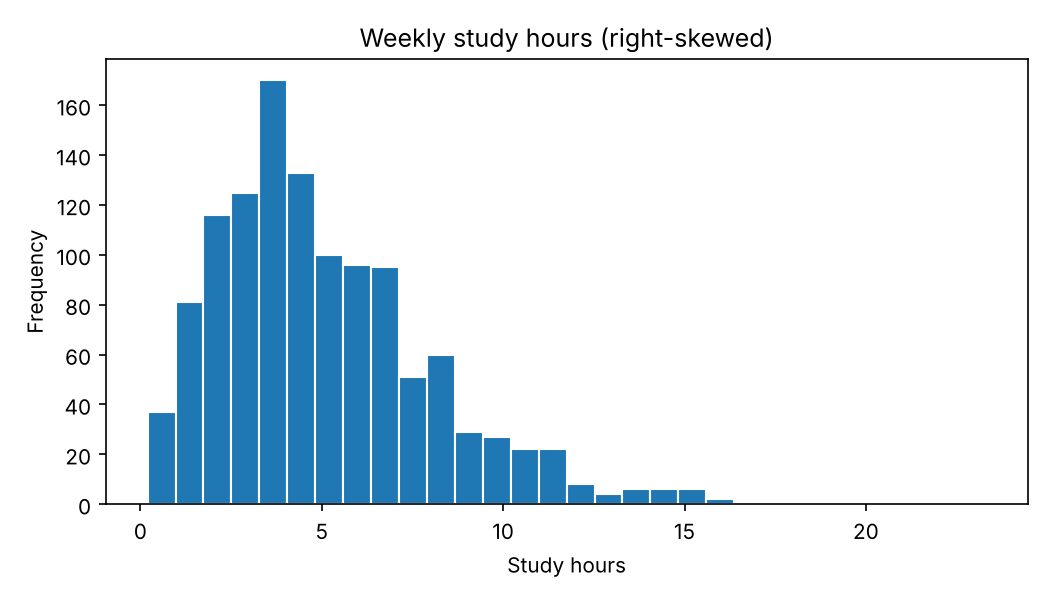

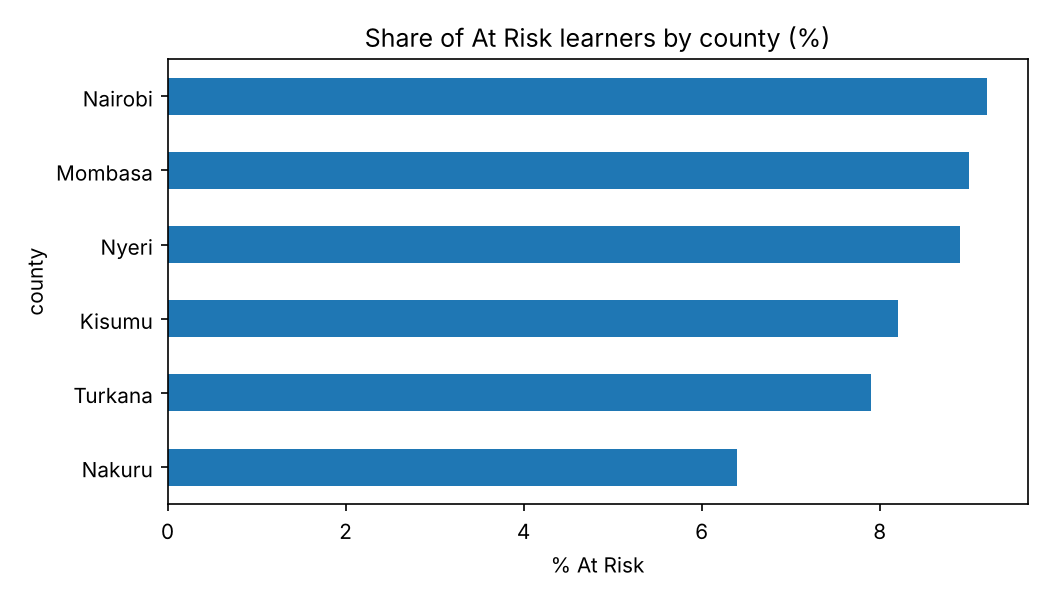

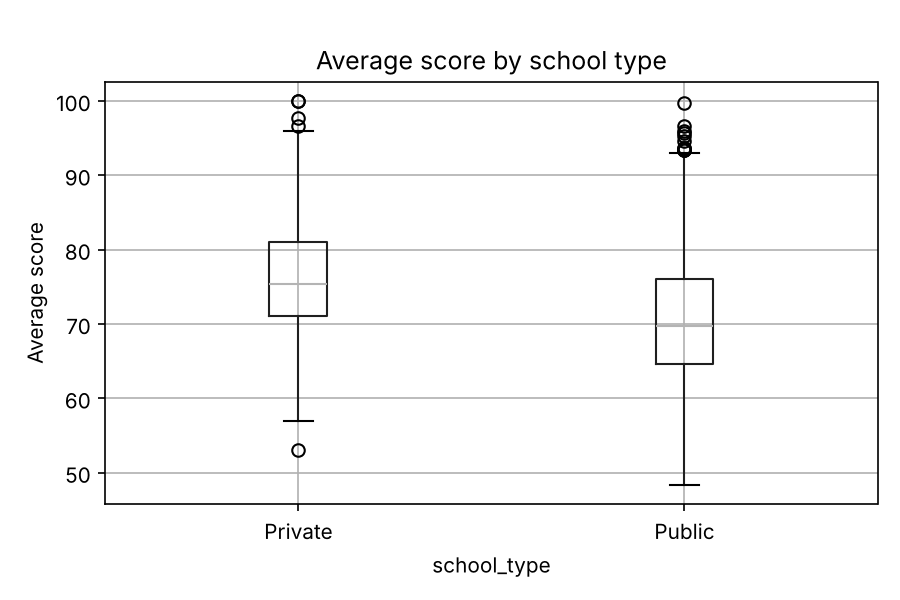

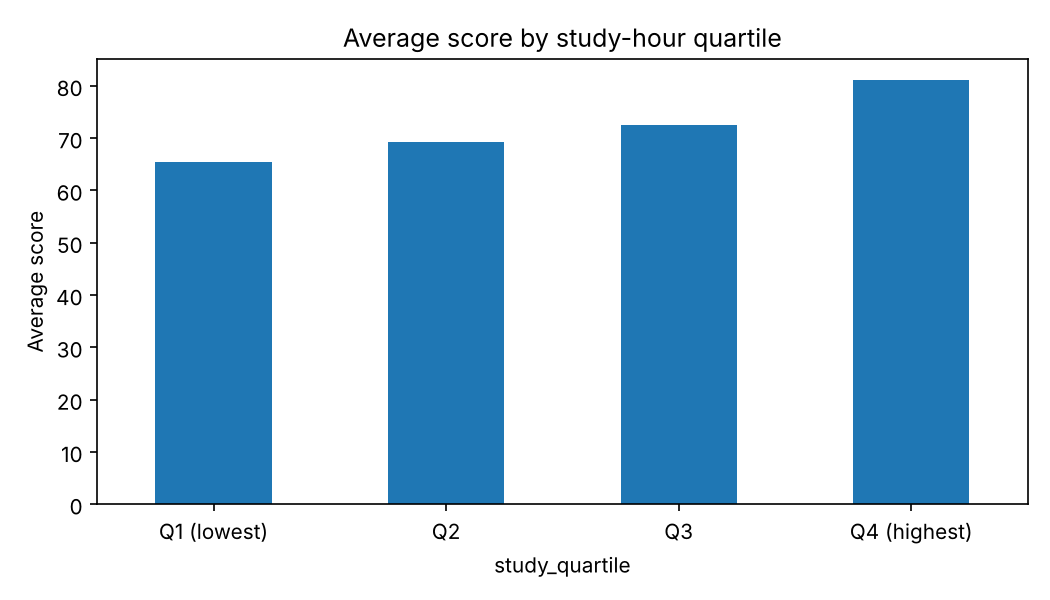

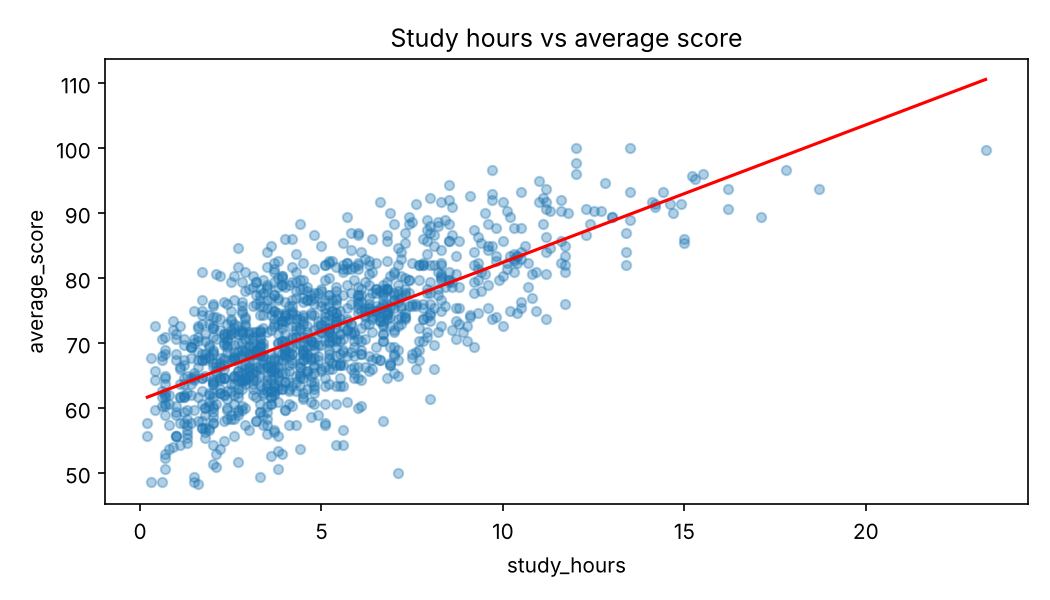

In [10]:
from IPython.display import Image, display
for f in sorted(os.listdir("figures")): display(Image(f"figures/{f}", width=520))

Charts support the findings: the score distribution sits mostly above the 60-point line with a 8.3% left tail (01); study hours are right-skewed (02); county At Risk shares are close together (03); the private box sits higher than public (04); scores climb steadily by study-hour quartile (05); the trend line rises about 2.1 points per hour with wide scatter (06).

## Task 9 · Findings, recommendations and limitations

### Five key insights
1. **Study hours is the strongest factor.** r = 0.70 with average score; ~2.1 points per hour. At Risk learners study a median 2.1 h vs 4.5 h for everyone.
2. **Attendance is the second factor, independent of study time.** r = 0.36; At Risk share is 23.9% at ≤70% attendance vs 2.3% at 91–100%.
3. **A school-type gap of 5.5 points persists** after controlling for attendance and study time (gap 3.6–7.8 in every band). 94 of 99 At Risk learners (94.9%) are in public schools.
4. **County and gender barely matter.** County At Risk shares span 6.4%–9.2%; Nairobi is highest (9.2%) but the spread is statistically indistinguishable from chance. Gender averages differ by 0.2 points.
5. **Risk is concentrated and identifiable.** Only 8.3% of learners are At Risk, and a simple rule — study ≤ 2.9 h/week **or** attendance ≤ 70% — flags 490 learners (40.8%) and captures **88.9%** of all At Risk learners.

### Recommendations for targeting the programme
1. **Target by behaviour, not by county.** Enrol learners with low study time (≤ 2.9 h/week) or low attendance (≤ 70%) — 490 learners capturing 88.9% of the At Risk group — and fund study-skills support (supervised homework clubs, study timetables) and attendance follow-up. Be aware the rule is broad: only 18.0% of flagged learners are currently below 60, so most are prevention cases rather than failures — a cheaper tier (attendance follow-up only) for the wider group and intensive support for those with both flags is a sensible split. Allocate budget in proportion to the number of flagged learners per county rather than by county rank.
2. **Prioritise public schools.** Adding a school-type filter (350 public-school learners flagged) still captures 83.8% of At Risk learners, and 94.9% of At Risk learners are in public schools; use it as the first-phase scope if the budget cannot cover all 490. Build an evaluation (before/after scores) into the pilot so causal impact can be measured.

### Limitations
This analysis is **observational and cross-sectional**: it shows associations, not causes, so extra study hours may reflect motivation or home support rather than producing the gain. Study hours are probably self-reported, and the dataset has no dates, so we cannot see whether learners improve or decline over time. Scores are capped at 100 and the performance bands are policy thresholds — moving the 60-point cutoff changes who is At Risk. Counties have only ~184–212 students (13–19 At Risk each), so county comparisons are imprecise, and important drivers such as household income, distance to school, teacher quality and prior attainment are missing. The data appear to come from a teaching dataset, so real-world relationships may be messier; findings should be validated on real county records before committing budget.